In [47]:
from migen import *
from misoc.cores.duc import CosSinGen


cs_sine_cos_in_width = 22
cs_sine_cos_out_width = 16

dut = CosSinGen(z=cs_sine_cos_in_width, x=cs_sine_cos_out_width, zl=9, xd=4)


x=[]
y=[]

def test():
    for n in range(2**16):
        yield
        x.append((yield dut.x))
        y.append((yield dut.y))
        yield dut.z.eq(n<<6)
    yield
    x.append((yield dut.x))
    y.append((yield dut.y))
    yield
    x.append((yield dut.x))
    y.append((yield dut.y))
    
    

run_simulation(dut,[test()],vcd_name="trs_signals.vcd")              


In [ ]:
! gtkwave trs_signals.vcd


GTKWave Analyzer v3.3.103 (w)1999-2019 BSI

[0] start time.
[1310725] end time.


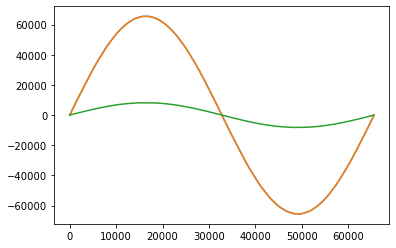

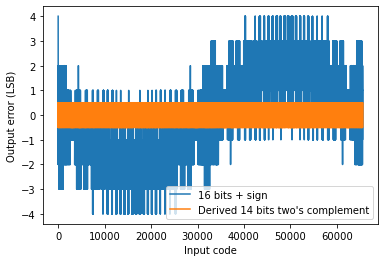

In [99]:
from matplotlib import pyplot as plt
import numpy as np

x_16b = np.array(y[2:])
x_14b = np.array(np.floor(np.array(y[2:])/8))
t = np.linspace(0,2**16-1,2**16)
x_ideal_16b =  np.round(np.sin((t-3)/(2**16)*2*np.pi ) * ((2**16-1)))
x_ideal_14b =  np.round(np.sin((t-3)/(2**16)*2*np.pi ) * (2**13-0.5))-0.5

plt.plot(x)

plt.plot(x_ideal_16b)
plt.plot(x_ideal_14b)
plt.figure()

error_16b = (x_16b-x_ideal_16b)[2:]
error_14b = (x_14b-x_ideal_14b)[2:]

plt.plot(error_16b)
plt.plot(error_14b)

plt.xlabel("Input code")
plt.ylabel("Output error (LSB)")
plt.legend(["16 bits + sign","Derived 14 bits two's complement"])
plt.savefig("Output_error.png")

0.0244140625